# 02. Model
Train on the June 2011 snapshot, test on the September 2011 snapshot (the future).
Compares a baseline, logistic regression and gradient boosting, with bootstrap confidence
intervals, a calibration check and feature importance.

**Input:** `features_train.csv`, `features_test.csv`. **Output:** `test_scored.csv`, `models/churn_model.joblib`.

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from churn_utils import ACTIVE_DAYS, metrics_with_ci, prior_shift

try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None          # falls back to scikit-learn gradient boosting

PROC, MODELS, SEED = Path("data/processed"), Path("models"), 42
MODELS.mkdir(exist_ok=True)

train = pd.read_csv(PROC / "features_train.csv", index_col="customer_id")
test = pd.read_csv(PROC / "features_test.csv", index_col="customer_id")
X_train, y_train = train.drop(columns="churn"), train["churn"]
X_test, y_test = test.drop(columns="churn"), test["churn"]

## 1. Train on the past, predict the future
Churn is the majority class in the training snapshot, so we use class weights (not SMOTE).

In [2]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
boosted = (XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                         colsample_bytree=0.8, scale_pos_weight=pos_weight,
                         eval_metric="logloss", random_state=SEED, n_jobs=-1)
           if XGBClassifier else
           HistGradientBoostingClassifier(learning_rate=0.05, max_depth=4,
                                          class_weight="balanced", random_state=SEED))
models = {
    "Dummy (base rate)": DummyClassifier(strategy="prior"),
    "Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Gradient Boosting": boosted,
}
preds = {n: m.fit(X_train, y_train).predict_proba(X_test)[:, 1] for n, m in models.items()}

## 2. Metrics with bootstrap 95% confidence intervals
"Active" customers (bought in the last 180 days) are the ones a retention team can still reach.

In [3]:
populations = {"All customers": np.ones(len(X_test), bool),
               f"Active only (bought in last {ACTIVE_DAYS} days)": (X_test["recency_days"] <= ACTIVE_DAYS).values}
for pop, mask in populations.items():
    rows = [{"model": n, **metrics_with_ci(y_test[mask], p[mask])} for n, p in preds.items()]
    print(f"\n=== {pop}: {mask.sum():,} customers, churn rate {y_test[mask].mean():.1%} ===")
    print(pd.DataFrame(rows).to_string(index=False))


=== All customers: 5,253 customers, churn rate 56.6% ===
              model             ROC-AUC              PR-AUC     Top-decile lift
  Dummy (base rate) 0.500 (0.500-0.500) 0.566 (0.553-0.579) 0.948 (0.920-1.071)
Logistic Regression 0.792 (0.780-0.805) 0.812 (0.797-0.827) 1.591 (1.540-1.641)
  Gradient Boosting 0.791 (0.778-0.802) 0.806 (0.790-0.821) 1.591 (1.534-1.637)

=== Active only (bought in last 180 days): 2,775 customers, churn rate 38.5% ===
              model             ROC-AUC              PR-AUC     Top-decile lift
  Dummy (base rate) 0.500 (0.500-0.500) 0.385 (0.368-0.402) 0.900 (0.869-1.140)
Logistic Regression 0.747 (0.729-0.765) 0.623 (0.595-0.660) 1.923 (1.803-2.095)
  Gradient Boosting 0.759 (0.742-0.780) 0.645 (0.614-0.676) 1.979 (1.859-2.145)


## 3. Can we trust the probabilities? (calibration)
Class weights shift probabilities, so we rescale them to the churn rate we expect.
*Here we use the test snapshot's own churn rate (hindsight). In production, use the latest
completed window and re-check as seasons change.*

Churn rate: train 68.0% | test 56.6%
Mean predicted: raw 60.6% | rescaled 56.6%
Brier score (lower is better): raw 0.1853 | rescaled 0.1841


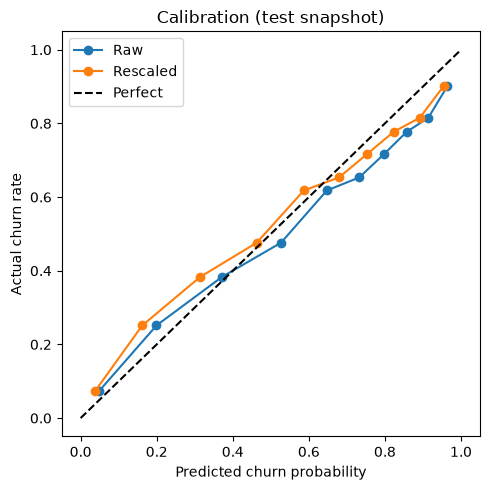

In [4]:
p_raw = preds["Gradient Boosting"]
p_adj = prior_shift(p_raw, to_rate=y_test.mean())
print(f"Churn rate: train {y_train.mean():.1%} | test {y_test.mean():.1%}")
print(f"Mean predicted: raw {p_raw.mean():.1%} | rescaled {p_adj.mean():.1%}")
print(f"Brier score (lower is better): raw {brier_score_loss(y_test, p_raw):.4f} | "
      f"rescaled {brier_score_loss(y_test, p_adj):.4f}")

fig, ax = plt.subplots(figsize=(5, 5))
for name, p in {"Raw": p_raw, "Rescaled": p_adj}.items():
    frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", label=name)
ax.plot([0, 1], [0, 1], "k--", label="Perfect")
ax.set(xlabel="Predicted churn probability", ylabel="Actual churn rate", title="Calibration (test snapshot)")
ax.legend()
plt.tight_layout()
plt.show()

## 4. What drives churn?

recency_days           0.0635
avg_gap_days           0.0245
total_items            0.0053
monetary               0.0049
frequency              0.0040
spend_last_90d         0.0024
avg_items_per_order    0.0024
tenure_days            0.0019
spend_last_30d         0.0010
orders_last_90d        0.0008
dtype: float64


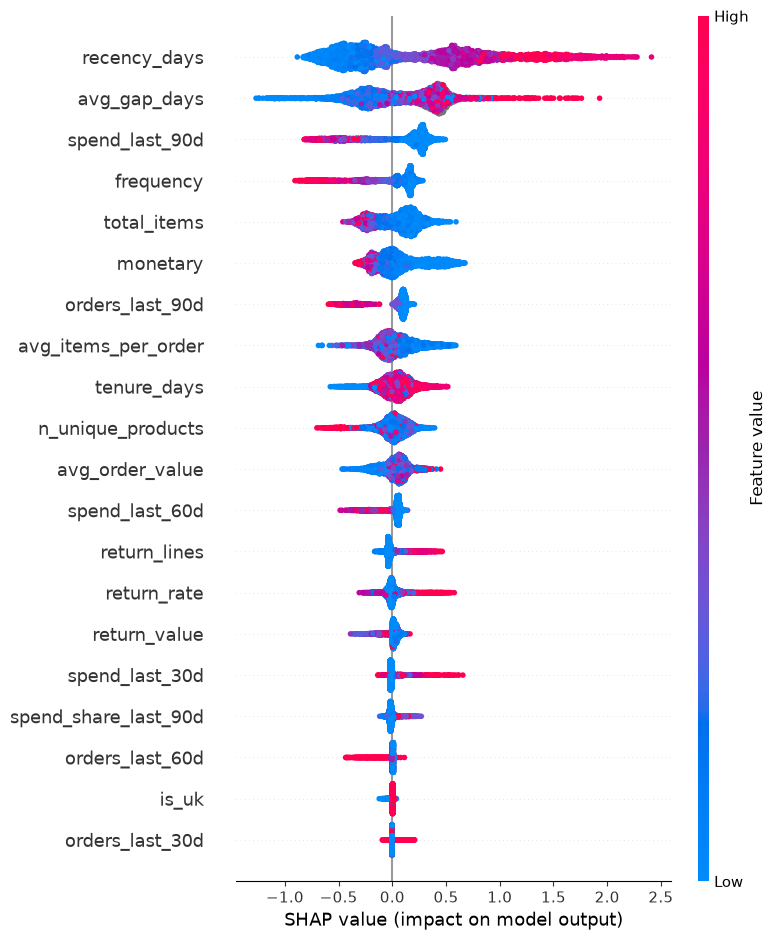

In [5]:
imp = permutation_importance(boosted, X_test, y_test, scoring="roc_auc", n_repeats=5,
                             random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(imp.head(10).round(4))

if XGBClassifier:
    try:
        import shap
        shap.summary_plot(shap.TreeExplainer(boosted).shap_values(X_test), X_test)
    except ImportError:
        print("pip install shap for the SHAP plot")

## 5. Save scored customers (used for the business analysis) and the model

In [6]:
test.assign(p_raw=p_raw, p_adj=p_adj).to_csv(PROC / "test_scored.csv")
joblib.dump({"model": boosted, "features": list(X_train.columns)}, MODELS / "churn_model.joblib")
print("Saved", len(test), "scored customers")

Saved 5253 scored customers
